**Food Delivery Orders Analytivs**

Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1. Data Import

In [3]:
df=pd.read_csv('Datasets\\food_delivery_orders_dataset.csv')

In [4]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (50000, 37)
Number of Rows: 50000
Number of Columns: 37


In [5]:
# 2. Column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['order_id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'order_date', 'order_hour', 'day_of_week', 'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type', 'restaurant_type', 'restaurant_primary_category', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'payment_method', 'tip_amount', 'distance_km', 'weather', 'traffic_level', 'delivery_partner_experience_months', 'delivery_partner_rating', 'restaurant_preparation_time_minutes', 'estimated_delivery_time_minutes', 'actual_delivery_time_minutes', 'late_delivery', 'order_status', 'cancellation_reason', 'customer_rating']


In [6]:
# 3. Data types and non-null counts
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  str    
 1   customer_id                          50000 non-null  str    
 2   restaurant_id                        50000 non-null  str    
 3   driver_id                            50000 non-null  str    
 4   order_timestamp                      50000 non-null  str    
 5   order_date                           50000 non-null  str    
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  str    
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  str    
 10  delivery_area                        50000 non-null  str    
 11  customer_age      

In [7]:
# 4. First 5 records
print("First 5 Records:")
display(df.head())

First 5 Records:


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,05-10-2025 15:54,05-10-2025,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,01-10-2025 20:00,01-10-2025,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,07-10-2025 18:24,07-10-2025,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,30-10-2025 16:54,30-10-2025,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,15-10-2025 18:34,15-10-2025,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [8]:
# 5. Random 5 records
print("Random 5 Records:")
display(df.sample(5, random_state=42))

Random 5 Records:


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
33553,ORD_033554,CUS_00002,RES_0026,DRV_0195,16-10-2025 03:25,16-10-2025,3,Thursday,0,City_C,...,Low,15,4.7,12,15,16.0,0.0,Completed,NaN,4.7
9427,ORD_009428,CUS_00006,RES_0009,DRV_0033,02-10-2025 13:10,02-10-2025,13,Thursday,0,City_B,...,Low,28,4.3,18,31,33.0,0.0,Completed,NaN,5.0
199,ORD_000200,CUS_00186,RES_0036,DRV_0031,18-10-2025 14:27,18-10-2025,14,Saturday,1,City_C,...,Medium,25,5.0,10,38,40.0,0.0,Completed,NaN,4.6
12447,ORD_012448,CUS_00001,RES_0119,DRV_0064,07-10-2025 12:46,07-10-2025,12,Tuesday,0,City_C,...,Medium,29,4.3,10,19,26.0,1.0,Completed,NaN,3.6
39489,ORD_039490,CUS_00076,RES_0005,DRV_0192,04-10-2025 09:10,04-10-2025,9,Saturday,1,City_A,...,Medium,6,4.8,16,26,31.0,0.0,Completed,NaN,4.4


In [9]:
# 6. Numerical summary
print("Numerical Summary:")
display(df.describe().round(2))

Numerical Summary:


,order_hour,is_weekend,customer_age,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,distance_km,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,customer_rating
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,49132.00,50000.00,50000.00,50000.00,50000.00,50000.00,49132.00,49132.00,49132.00
mean,14.47,0.27,27.69,4.21,2.91,30.90,4.50,4.13,1.47,3.08,38.17,1.61,4.73,29.73,4.50,15.55,30.95,35.15,0.37,4.30
std,5.23,0.44,7.54,0.45,2.03,27.07,6.43,3.64,1.38,2.30,31.05,2.88,2.78,17.41,0.35,7.36,12.83,14.70,0.48,0.53
min,0.00,0.00,18.00,2.80,1.00,5.10,0.00,0.57,0.13,0.00,4.87,0.00,0.80,1.00,3.20,5.00,8.00,10.00,0.00,1.80
25%,11.00,0.00,21.00,3.90,1.00,13.10,0.00,1.73,0.58,0.00,17.43,0.00,2.80,14.00,4.30,10.00,22.00,25.00,0.00,4.00
50%,14.00,0.00,27.00,4.20,2.00,22.82,0.00,2.89,1.04,3.50,28.35,0.00,4.10,29.00,4.50,14.00,28.00,33.00,0.00,4.40
75%,19.00,1.00,33.00,4.60,4.00,40.12,10.00,5.39,1.89,4.50,48.66,2.28,5.90,44.00,4.80,19.00,37.00,42.00,1.00,4.70
max,23.00,1.00,55.00,5.00,10.00,362.98,20.00,50.82,25.21,12.00,443.21,53.65,20.00,60.00,5.00,73.00,128.00,172.00,1.00,5.00


In [10]:
# 7. Categorical summary
print("Categorical Summary:")
display(df.describe(include="object"))

Categorical Summary:


C:\Users\Gokul\AppData\Local\Temp\ipykernel_17864\1280986397.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,day_of_week,city,delivery_area,customer_type,restaurant_type,restaurant_primary_category,payment_method,weather,traffic_level,order_status,cancellation_reason
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,868
unique,50000,4979,250,200,25459,30,7,4,40,3,4,6,3,4,3,2,5
top,ORD_000001,CUS_00001,RES_0001,DRV_0066,19-10-2025 13:00,23-10-2025,Thursday,City_A,City_A_Area_1,Regular,Fast Food,Burger,Credit Card,Clear,Medium,Completed,Driver Unassigned
freq,1,4510,8837,315,9,1741,8472,19888,2056,25098,27593,16184,24971,28248,19522,49132,386


2. Data Cleaning

Missing values: count, percentage, and appropriate treatment.


In [11]:
df.isnull().sum()

order_id                                   0
customer_id                                0
restaurant_id                              0
driver_id                                  0
order_timestamp                            0
order_date                                 0
order_hour                                 0
day_of_week                                0
is_weekend                                 0
city                                       0
delivery_area                              0
customer_age                               0
customer_type                              0
restaurant_type                            0
restaurant_primary_category                0
restaurant_rating                          0
items_count                                0
subtotal                                   0
discount_percent                           0
tax_amount                                 0
service_fee                                0
delivery_fee                               0
order_tota

In [12]:

# Check missing values by order status

columns_to_check = [
    'customer_rating',
    'tip_amount',
    'actual_delivery_time_minutes',
    'late_delivery',
    'cancellation_reason'
]

for col in columns_to_check:
    print(f"\n{col}")
    print(pd.crosstab(
        df['order_status'],
        df[col].isna(),
        margins=True
    ))



customer_rating
customer_rating  False  True    All
order_status                       
Cancelled            0   868    868
Completed        49132     0  49132
All              49132   868  50000

tip_amount
tip_amount    False  True    All
order_status                    
Cancelled         0   868    868
Completed     49132     0  49132
All           49132   868  50000

actual_delivery_time_minutes
actual_delivery_time_minutes  False  True    All
order_status                                    
Cancelled                         0   868    868
Completed                     49132     0  49132
All                           49132   868  50000

late_delivery
late_delivery  False  True    All
order_status                     
Cancelled          0   868    868
Completed      49132     0  49132
All            49132   868  50000

cancellation_reason
cancellation_reason  False   True    All
order_status                            
Cancelled              868      0    868
Completed             

In [13]:
# Verify that missing values are associated with order status
assert df.loc[
    df['order_status'] == 'Cancelled',
    ['customer_rating', 'tip_amount',
     'actual_delivery_time_minutes', 'late_delivery']
].isna().all().all()

assert df.loc[
    df['order_status'] == 'Completed',
    'cancellation_reason'
].isna().all()

print("Missing-value checks passed.")

Missing-value checks passed.


In [14]:
# Missing-value analysis
missing_count = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': (missing_count / len(df)) * 100
})

# Display only columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(by='Missing Count', ascending=False)

missing_summary['Missing Percentage'] = (
    missing_summary['Missing Percentage'].round(2)
)

print(missing_summary)

                              Missing Count  Missing Percentage
cancellation_reason                   49132               98.26
tip_amount                              868                1.74
actual_delivery_time_minutes            868                1.74
late_delivery                           868                1.74
customer_rating                         868                1.74


The dataset contains 50,000 records. Five columns contain missing values: cancellation_reason, tip_amount, actual_delivery_time_minutes, late_delivery, and customer_rating.

The cancellation_reason column has 49,132 missing values (98.26%), corresponding to completed orders for which cancellation reasons are not applicable. The remaining four columns each contain 868 missing values (1.74%), corresponding to cancelled orders.

These missing values are associated with the order status and represent information that is not applicable to those orders. Therefore, the missing values will be retained rather than automatically replaced with zero. During subsequent analysis, appropriate filters will be applied to ensure accurate calculations of customer ratings, tips, delivery times, late-delivery rates, and cancellation reasons.

Duplicates: exact duplicate rows and duplicate identifiers.


In [15]:

# Check exact duplicate rows
exact_duplicates = df.duplicated().sum()

print("Total rows:", len(df))
print("Exact duplicate rows:", exact_duplicates)
print(
    "Duplicate percentage:",
    round((exact_duplicates / len(df)) * 100, 2), "%"
)


Total rows: 50000
Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [16]:

# Check duplicate identifiers
identifier_columns = [
    'order_id',
    'customer_id',
    'restaurant_id',
    'driver_id'
]

for col in identifier_columns:
    duplicate_count = df[col].duplicated().sum()
    duplicate_percentage = (duplicate_count / len(df)) * 100

    print(f"\nColumn: {col}")
    print(f"Repeated values: {duplicate_count}")
    print(f"Percentage: {duplicate_percentage:.2f}%")
    print(f"Unique values: {df[col].nunique()}")



Column: order_id
Repeated values: 0
Percentage: 0.00%
Unique values: 50000



Column: customer_id
Repeated values: 45021
Percentage: 90.04%
Unique values: 4979

Column: restaurant_id
Repeated values: 49750
Percentage: 99.50%
Unique values: 250

Column: driver_id
Repeated values: 49800
Percentage: 99.60%
Unique values: 200


In [17]:

# Check order ID uniqueness
duplicate_order_mask = df['order_id'].duplicated(keep=False)

duplicate_orders = df.loc[
    duplicate_order_mask
].sort_values('order_id')

print("Unique order IDs:", df['order_id'].nunique())
print("Duplicate order ID rows:", duplicate_order_mask.sum())
print("\nDuplicate order records:")
print(duplicate_orders.head(10))


Unique order IDs: 50000
Duplicate order ID rows: 0

Duplicate order records:
Empty DataFrame
Columns: [order_id, customer_id, restaurant_id, driver_id, order_timestamp, order_date, order_hour, day_of_week, is_weekend, city, delivery_area, customer_age, customer_type, restaurant_type, restaurant_primary_category, restaurant_rating, items_count, subtotal, discount_percent, tax_amount, service_fee, delivery_fee, order_total, payment_method, tip_amount, distance_km, weather, traffic_level, delivery_partner_experience_months, delivery_partner_rating, restaurant_preparation_time_minutes, estimated_delivery_time_minutes, actual_delivery_time_minutes, late_delivery, order_status, cancellation_reason, customer_rating]
Index: []

[0 rows x 37 columns]


The dataset contains 50,000 records and 37 columns. The duplicate analysis identified zero exact duplicate rows (0.00%) and zero duplicate order IDs. All 50,000 orders have unique identifiers, indicating that there are no apparent duplicate orders based on order_id.

The customer_id column contains 45,021 repeated occurrences (90.04%), with 4,979 unique customers. Similarly, restaurant_id contains 49,750 repeated occurrences (99.50%), representing 250 unique restaurants, while driver_id contains 49,800 repeated occurrences (99.60%), representing 200 unique drivers.

These repeated identifiers are expected in an order-level dataset because customers can place multiple orders, restaurants can receive multiple orders, and drivers can handle multiple deliveries. Therefore, these repetitions should not be removed. Since no exact duplicate rows or duplicate order IDs were detected, no duplicate-row removal is required at this stage.

Data types: convert dates, numeric fields, and categorical variables.

In [18]:
df.dtypes

order_id                                   str
customer_id                                str
restaurant_id                              str
driver_id                                  str
order_timestamp                            str
order_date                                 str
order_hour                               int64
day_of_week                                str
is_weekend                               int64
city                                       str
delivery_area                              str
customer_age                             int64
customer_type                              str
restaurant_type                            str
restaurant_primary_category                str
restaurant_rating                      float64
items_count                              int64
subtotal                               float64
discount_percent                         int64
tax_amount                             float64
service_fee                            float64
delivery_fee 

In [19]:

# 1. Convert date columns
# Convert dates using their exact formats
df['order_timestamp'] = pd.to_datetime(
    df['order_timestamp'],
    format='%d-%m-%Y %H:%M',
    errors='raise'
)

# Convert order date: DD-MM-YYYY
df['order_date'] = pd.to_datetime(
    df['order_date'],
    format='%d-%m-%Y',
    errors='raise'
)


In [20]:

# 2. Convert categorical columns
categorical_columns = [
    'customer_id',
    'restaurant_id',
    'driver_id',
    'day_of_week',
    'city',
    'delivery_area',
    'customer_type',
    'restaurant_type',
    'restaurant_primary_category',
    'payment_method',
    'weather',
    'traffic_level',
    'order_status',
    'cancellation_reason'
]

for col in categorical_columns:
    df[col] = df[col].astype('category')



In [21]:
# 3. Convert Boolean/binary field
df['is_weekend'] = df['is_weekend'].astype('bool')



In [22]:

print(df.dtypes)

order_id                                          str
customer_id                                  category
restaurant_id                                category
driver_id                                    category
order_timestamp                        datetime64[us]
order_date                             datetime64[us]
order_hour                                      int64
day_of_week                                  category
is_weekend                                       bool
city                                         category
delivery_area                                category
customer_age                                    int64
customer_type                                category
restaurant_type                              category
restaurant_primary_category                  category
restaurant_rating                             float64
items_count                                     int64
subtotal                                      float64
discount_percent            

In [23]:

print("Date conversion failures:")
print(df[['order_timestamp', 'order_date']].isna().sum())

print("\nAll missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])




Date conversion failures:
order_timestamp    0
order_date         0
dtype: int64

All missing values:
tip_amount                        868
actual_delivery_time_minutes      868
late_delivery                     868
cancellation_reason             49132
customer_rating                   868
dtype: int64


In [24]:
print(df[['order_timestamp', 'order_date']].dtypes)

print("\nMissing dates after conversion:")
print(df[['order_timestamp', 'order_date']].isna().sum())


order_timestamp    datetime64[us]
order_date         datetime64[us]
dtype: object

Missing dates after conversion:
order_timestamp    0
order_date         0
dtype: int64


Column names: standardize spaces, symbols, and capitalization.


In [25]:
print("Total columns:", len(df.columns))
print("Unique column names:", df.columns.nunique())
print("Column names:")
print(df.columns.tolist())

Total columns: 37
Unique column names: 37
Column names:
['order_id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'order_date', 'order_hour', 'day_of_week', 'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type', 'restaurant_type', 'restaurant_primary_category', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'payment_method', 'tip_amount', 'distance_km', 'weather', 'traffic_level', 'delivery_partner_experience_months', 'delivery_partner_rating', 'restaurant_preparation_time_minutes', 'estimated_delivery_time_minutes', 'actual_delivery_time_minutes', 'late_delivery', 'order_status', 'cancellation_reason', 'customer_rating']


Validate financial calculations, statuses, and currency consistency.


In [26]:

# Work on a copy so the original dataset remains unchanged
df_check = df.copy()

# Calculate expected order total
df_check['discount_amount_check'] = (
    df_check['subtotal'] * df_check['discount_percent'] / 100
)

df_check['expected_order_total'] = (
    df_check['subtotal']
    - df_check['discount_amount_check']
    + df_check['tax_amount']
    + df_check['service_fee']
    + df_check['delivery_fee']
)

# Compare expected total with recorded total
df_check['total_difference'] = (
    df_check['order_total'] - df_check['expected_order_total']
).round(2)

tolerance = 0.02

financial_mismatch = (
    df_check['total_difference'].abs() > tolerance
)

print("Financial validation summary")
print("Total orders:", len(df_check))
print("Orders with matching totals:",
      (~financial_mismatch).sum())
print("Orders with mismatched totals:",
      financial_mismatch.sum())
print("Mismatch percentage:",
      round(financial_mismatch.mean() * 100, 2), "%")

# Inspect mismatched records
print("\nSample mismatched orders:")
print(
    df_check.loc[
        financial_mismatch,
        ['order_id', 'subtotal', 'discount_percent',
         'tax_amount', 'service_fee', 'delivery_fee',
         'order_total', 'expected_order_total',
         'total_difference']
    ].head(10)
)

Financial validation summary
Total orders: 50000
Orders with matching totals: 50000
Orders with mismatched totals: 0
Mismatch percentage: 0.0 %

Sample mismatched orders:
Empty DataFrame
Columns: [order_id, subtotal, discount_percent, tax_amount, service_fee, delivery_fee, order_total, expected_order_total, total_difference]
Index: []


In [27]:
#2. Validate monetary values and discount percentages
money_columns = [
    'subtotal', 'tax_amount', 'service_fee',
    'delivery_fee', 'order_total', 'tip_amount'
]

print("Negative monetary values:")
print((df[money_columns] < 0).sum())

print("\nDiscount percentage outside 0–100:")
print(
    (
        (df['discount_percent'] < 0) |
        (df['discount_percent'] > 100)
    ).sum()
)

print("\nFinancial column summary:")
print(df[money_columns + ['discount_percent']].describe().round(2))

Negative monetary values:
subtotal        0
tax_amount      0
service_fee     0
delivery_fee    0
order_total     0
tip_amount      0
dtype: int64

Discount percentage outside 0–100:
0

Financial column summary:
       subtotal  tax_amount  service_fee  delivery_fee  order_total  \
count  50000.00    50000.00     50000.00      50000.00     50000.00   
mean      30.90        4.13         1.47          3.08        38.17   
std       27.07        3.64         1.38          2.30        31.05   
min        5.10        0.57         0.13          0.00         4.87   
25%       13.10        1.73         0.58          0.00        17.43   
50%       22.82        2.89         1.04          3.50        28.35   
75%       40.12        5.39         1.89          4.50        48.66   
max      362.98       50.82        25.21         12.00       443.21   

       tip_amount  discount_percent  
count    49132.00          50000.00  
mean         1.61              4.50  
std          2.88              6.4

In [28]:
#3. Validate order statuses
# Inspect status labels and counts
print("Order status counts:")
print(df['order_status'].value_counts(dropna=False))

print("\nOrder status percentages:")
print(
    (df['order_status'].value_counts(normalize=True) * 100)
    .round(2)
)

# Check whether unexpected or missing statuses exist
expected_statuses = {'Completed', 'Cancelled'}

unexpected_statuses = (
    set(df['order_status'].dropna().unique())
    - expected_statuses
)

print("\nUnexpected statuses:", unexpected_statuses)
print("Missing statuses:", df['order_status'].isna().sum())

# Check completed orders have actual delivery times
completed = df['order_status'].eq('Completed')
cancelled = df['order_status'].eq('Cancelled')

print("\nCompleted orders missing actual delivery time:",
      (completed & df['actual_delivery_time_minutes'].isna()).sum())

print("Cancelled orders with actual delivery time recorded:",
      (cancelled & df['actual_delivery_time_minutes'].notna()).sum())

print("Completed orders missing cancellation reason:",
      (completed & df['cancellation_reason'].notna()).sum())

print("Cancelled orders missing cancellation reason:",
      (cancelled & df['cancellation_reason'].isna()).sum())

Order status counts:
order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

Order status percentages:
order_status
Completed    98.26
Cancelled     1.74
Name: proportion, dtype: float64

Unexpected statuses: set()
Missing statuses: 0

Completed orders missing actual delivery time: 0
Cancelled orders with actual delivery time recorded: 0
Completed orders missing cancellation reason: 0
Cancelled orders missing cancellation reason: 0


In [29]:
#4. Validate currency consistency
money_columns = [
    'subtotal', 'tax_amount', 'service_fee',
    'delivery_fee', 'order_total', 'tip_amount'
]

print("Monetary column data types:")
print(df[money_columns].dtypes)

print("\nNon-numeric values after conversion check:")
for col in money_columns:
    numeric_values = pd.to_numeric(df[col], errors='coerce')
    invalid = df[col].notna() & numeric_values.isna()
    print(f"{col}: {invalid.sum()}")

Monetary column data types:
subtotal        float64
tax_amount      float64
service_fee     float64
delivery_fee    float64
order_total     float64
tip_amount      float64
dtype: object

Non-numeric values after conversion check:
subtotal: 0
tax_amount: 0
service_fee: 0
delivery_fee: 0
order_total: 0
tip_amount: 0


In [30]:
#5. Final validation summary
validation_summary = pd.Series({
    'Total records': len(df),
    'Unique order IDs': df['order_id'].nunique(),
    'Missing order statuses': df['order_status'].isna().sum(),
    'Unexpected order statuses': len(unexpected_statuses),
    'Financial total mismatches': int(financial_mismatch.sum()),
    'Negative monetary values': int((df[money_columns] < 0).sum().sum()),
    'Invalid discount percentages': int(
        (
            (df['discount_percent'] < 0) |
            (df['discount_percent'] > 100)
        ).sum()
    )
})

print(validation_summary)

Total records                   50000
Unique order IDs                50000
Missing order statuses              0
Unexpected order statuses           0
Financial total mismatches          0
Negative monetary values            0
Invalid discount percentages        0
dtype: int64


In [31]:
rating_columns = [
    'restaurant_rating',
    'delivery_partner_rating',
    'customer_rating'
]

for col in rating_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Missing:", df[col].isna().sum())

    invalid = (
        df[col].notna()
        & ~df[col].between(1, 5)
    )
    print("Outside 1-5 scale:", invalid.sum())


restaurant_rating
Minimum: 2.8
Maximum: 5.0
Missing: 0
Outside 1-5 scale: 0

delivery_partner_rating
Minimum: 3.2
Maximum: 5.0
Missing: 0
Outside 1-5 scale: 0

customer_rating
Minimum: 1.8
Maximum: 5.0
Missing: 868
Outside 1-5 scale: 0


In [32]:
#Validate delivery times and distances
# Columns that should normally be positive
positive_columns = [
    'distance_km',
    'items_count',
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
    'actual_delivery_time_minutes'
]

for col in positive_columns:
    values = df[col].dropna()

    print(f"\n{col}")
    print("Zero values:", (values == 0).sum())
    print("Negative values:", (values < 0).sum())
    print("Missing values:", df[col].isna().sum())


distance_km
Zero values: 0
Negative values: 0
Missing values: 0

items_count
Zero values: 0
Negative values: 0
Missing values: 0

restaurant_preparation_time_minutes
Zero values: 0
Negative values: 0
Missing values: 0

estimated_delivery_time_minutes
Zero values: 0
Negative values: 0
Missing values: 0

actual_delivery_time_minutes
Zero values: 0
Negative values: 0
Missing values: 868


In [33]:
#Check whether estimated and actual delivery times are reasonable
time_columns = [
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
    'actual_delivery_time_minutes'
]

print(df[time_columns].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).round(2))

# Check whether actual delivery exceeded the estimate
completed_df = df[df['order_status'] == 'Completed'].copy()

completed_df['delivery_time_difference'] = (
    completed_df['actual_delivery_time_minutes']
    - completed_df['estimated_delivery_time_minutes']
)

print("\nActual delivery exceeded estimate:")
print(
    (completed_df['delivery_time_difference'] > 0).sum()
)

print("\nActual delivery was equal to estimate:")
print(
    (completed_df['delivery_time_difference'] == 0).sum()
)

print("\nActual delivery was below estimate:")
print(
    (completed_df['delivery_time_difference'] < 0).sum()
)

       restaurant_preparation_time_minutes  estimated_delivery_time_minutes  \
count                             50000.00                         50000.00   
mean                                 15.55                            30.95   
std                                   7.36                            12.83   
min                                   5.00                             8.00   
1%                                    5.00                            13.00   
25%                                  10.00                            22.00   
50%                                  14.00                            28.00   
75%                                  19.00                            37.00   
95%                                  29.00                            55.00   
99%                                  39.00                            74.00   
max                                  73.00                           128.00   

       actual_delivery_time_minutes  
count        

In [34]:
completed_df = df[df['order_status'] == 'Completed'].copy()

# Calculate late status using the time comparison
completed_df['calculated_late'] = (
    completed_df['actual_delivery_time_minutes']
    > completed_df['estimated_delivery_time_minutes']
)

# Compare existing and calculated flags
print("Existing late_delivery values:")
print(completed_df['late_delivery'].value_counts(dropna=False))

print("\nCross-tabulation:")
print(pd.crosstab(
    completed_df['late_delivery'],
    completed_df['calculated_late'],
    rownames=['Existing late_delivery'],
    colnames=['Calculated late']
))

# Count mismatches, assuming late_delivery is coded 0/1
existing_late = completed_df['late_delivery'].astype(int).astype(bool)

mismatches = existing_late != completed_df['calculated_late']

print("\nFlag mismatches:", mismatches.sum())
print("Mismatch percentage:", round(mismatches.mean() * 100, 2), "%")

Existing late_delivery values:
late_delivery
0.0    31164
1.0    17968
Name: count, dtype: int64

Cross-tabulation:
Calculated late         False  True 
Existing late_delivery              
0.0                     11833  19331
1.0                         0  17968

Flag mismatches: 19331
Mismatch percentage: 39.35 %


In [35]:
completed_df = df[df['order_status'] == 'Completed'].copy()

completed_df['delay_minutes'] = (
    completed_df['actual_delivery_time_minutes']
    - completed_df['estimated_delivery_time_minutes']
)

# Orders that exceed the estimate but are marked not late
mismatch_df = completed_df[
    (completed_df['delay_minutes'] > 0) &
    (completed_df['late_delivery'] == 0)
]

print("Mismatched orders:", len(mismatch_df))

print("\nDelay distribution for mismatched orders:")
print(mismatch_df['delay_minutes'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).round(2))

print("\nSample mismatched records:")
print(
    mismatch_df[
        ['order_id', 'estimated_delivery_time_minutes',
         'actual_delivery_time_minutes',
         'delay_minutes', 'late_delivery']
    ].head(10)
)

Mismatched orders: 19331

Delay distribution for mismatched orders:
count    19331.00
mean         3.03
std          1.40
min          1.00
25%          2.00
50%          3.00
75%          4.00
90%          5.00
95%          5.00
max          5.00
Name: delay_minutes, dtype: float64

Sample mismatched records:
      order_id  estimated_delivery_time_minutes  actual_delivery_time_minutes  \
0   ORD_000001                               25                          29.0   
1   ORD_000002                               20                          24.0   
6   ORD_000007                               27                          31.0   
7   ORD_000008                               20                          22.0   
8   ORD_000009                               37                          40.0   
11  ORD_000012                               25                          28.0   
13  ORD_000014                               35                          39.0   
14  ORD_000015                          

In [36]:
completed_df = df[df['order_status'] == 'Completed'].copy()

completed_df['delay_minutes'] = (
    completed_df['actual_delivery_time_minutes']
    - completed_df['estimated_delivery_time_minutes']
)

# Test several possible delay thresholds
for threshold in range(1, 11):
    calculated_late = completed_df['delay_minutes'] > threshold

    mismatches = (
        calculated_late != completed_df['late_delivery'].astype(bool)
    ).sum()

    print(
        f"Threshold > {threshold:2} minutes: "
        f"{mismatches:,} mismatches"
    )

Threshold >  1 minutes: 15,687 mismatches
Threshold >  2 minutes: 11,814 mismatches
Threshold >  3 minutes: 7,840 mismatches
Threshold >  4 minutes: 3,828 mismatches
Threshold >  5 minutes: 0 mismatches
Threshold >  6 minutes: 3,534 mismatches
Threshold >  7 minutes: 6,535 mismatches
Threshold >  8 minutes: 9,105 mismatches
Threshold >  9 minutes: 11,168 mismatches
Threshold > 10 minutes: 12,725 mismatches


3. Data Exploration


1. Which restaurant categories generate the highest revenue?

In [37]:

# Filter completed orders
completed_df = df[df['order_status'] == 'Completed'].copy()

# Calculate total revenue by restaurant category
category_revenue = (
    completed_df.groupby('restaurant_primary_category')['order_total']
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by restaurant category:")
print(category_revenue.round(2))

print("\nTop 5 restaurant categories by revenue:")
print(category_revenue.head(5).round(2))

Revenue by restaurant category:
restaurant_primary_category
Burger     538745.37
Local      466744.22
Dessert    365977.32
Asian      173101.45
Pizza      165618.95
Healthy    163989.26
Name: order_total, dtype: float64

Top 5 restaurant categories by revenue:
restaurant_primary_category
Burger     538745.37
Local      466744.22
Dessert    365977.32
Asian      173101.45
Pizza      165618.95
Name: order_total, dtype: float64


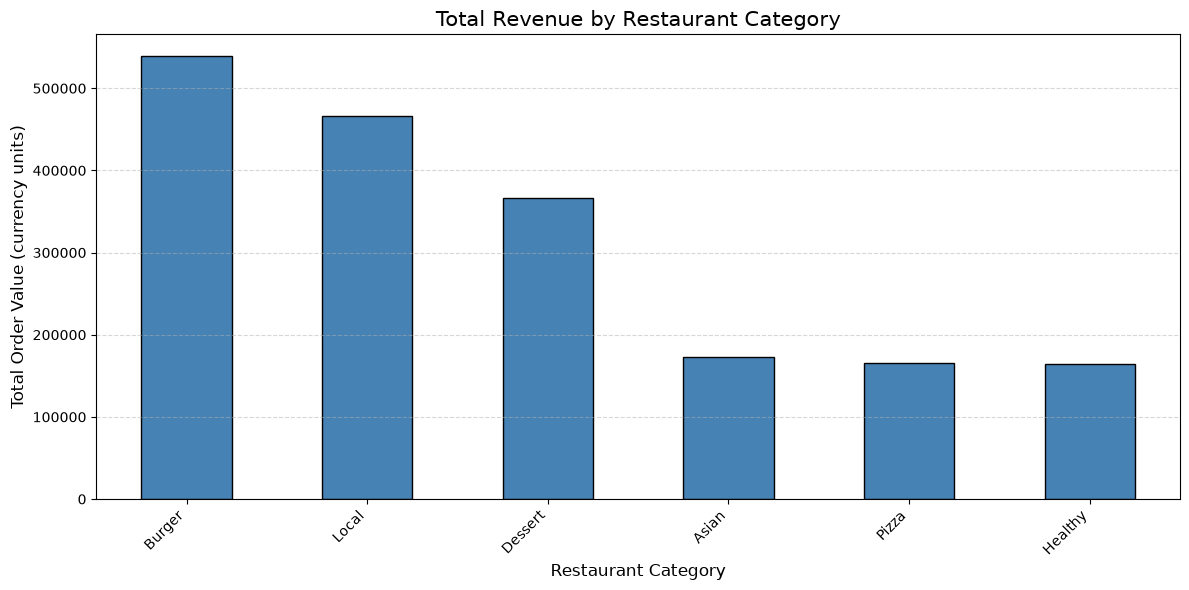

In [38]:
plt.figure(figsize=(12, 6))

category_revenue.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Revenue by Restaurant Category', fontsize=15)
plt.xlabel('Restaurant Category', fontsize=12)
plt.ylabel('Total Order Value (currency units)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Burger category generates the highest total revenue, followed by Local and Dessert categories. Asian, Pizza, and Healthy categories contribute comparatively less revenue

2. What is the average order value across different restaurant categories?

In [39]:
completed_df = df[df['order_status'] == 'Completed'].copy()

category_aov = (
    completed_df.groupby('restaurant_primary_category')['order_total']
    .mean()
    .sort_values(ascending=False)
)

print("Average Order Value by Restaurant Category:")
print(category_aov.round(2))

Average Order Value by Restaurant Category:
restaurant_primary_category
Healthy    46.31
Asian      46.23
Pizza      41.14
Dessert    38.86
Local      37.35
Burger     33.87
Name: order_total, dtype: float64


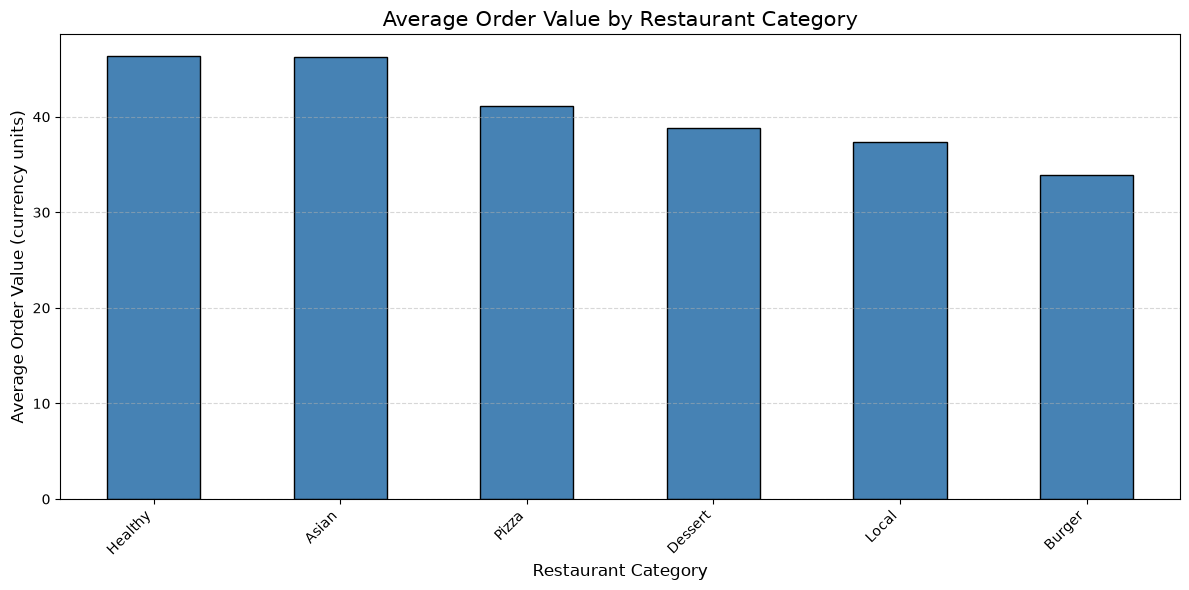

In [40]:
plt.figure(figsize=(12, 6))

category_aov.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Order Value by Restaurant Category', fontsize=15)
plt.xlabel('Restaurant Category', fontsize=12)
plt.ylabel('Average Order Value (currency units)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Healthy and Asian restaurant categories have the highest average order value, at approximately 46 currency units each, followed by Pizza at around 41. Dessert averages approximately 39, Local around 37, and Burger has the lowest average order value at approximately 34 currency units.

This may be because customers spend more per order at Healthy and Asian restaurants

3. Which payment methods are associated with the highest total sales?

In [41]:
completed_df = df[df['order_status'] == 'Completed'].copy()

payment_sales = (
    completed_df.groupby('payment_method')['order_total']
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Payment Method:")
print(payment_sales.round(2))

print("\nPayment method with the highest total sales:")
print(payment_sales.idxmax(), "-", round(payment_sales.max(), 2))

Total Sales by Payment Method:
payment_method
Credit Card       932702.68
Cash              571546.49
Digital Wallet    369927.40
Name: order_total, dtype: float64

Payment method with the highest total sales:
Credit Card - 932702.68


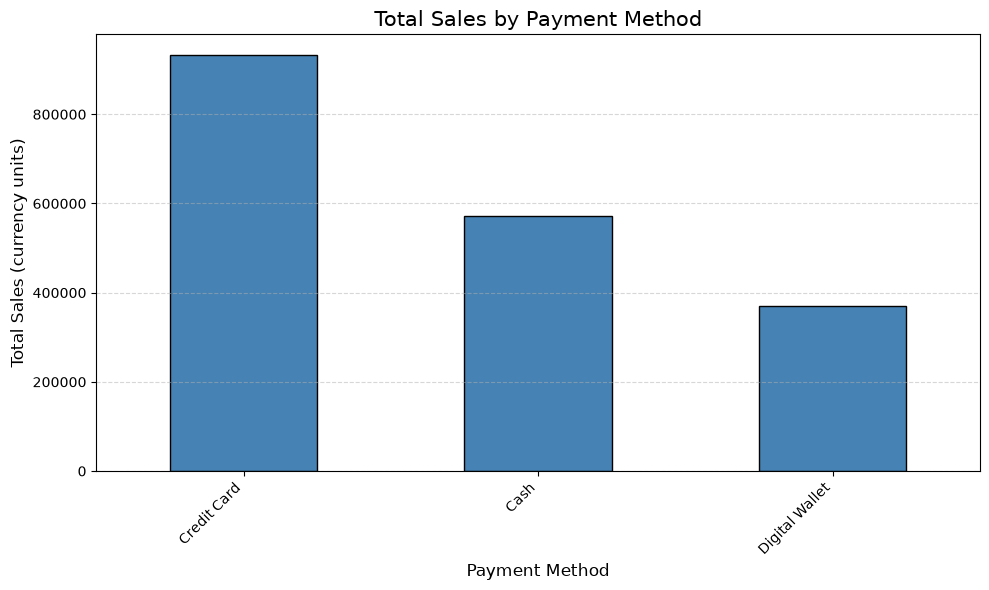

In [42]:
plt.figure(figsize=(10, 6))

payment_sales.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Sales by Payment Method', fontsize=15)
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Total Sales (currency units)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Credit Card payments generate the highest total sales, at approximately 930,000 currency units, followed by Cash at around 570,000 and Digital Wallet at approximately 370,000.

This indicates that credit card payments contribute the largest share of sales among the three payment methods. One possible reason is that customers using credit cards may place more orders or spend more per order.

4. Which hours or time periods have the highest number of orders?

In [43]:
hourly_orders = (
    df.groupby('order_hour')['order_id']
    .nunique()
    .sort_index()
)

print("Number of Orders by Hour:")
print(hourly_orders)

print("\nTop 5 Hours by Order Volume:")
print(hourly_orders.sort_values(ascending=False).head(5))

Number of Orders by Hour:
order_hour
0      429
1      437
2      408
3      407
4      425
5      404
6      868
7     1301
8     1675
9     2106
10    2618
11    3441
12    4208
13    3836
14    3098
15    1610
16    1725
17    2121
18    3803
19    4746
20    4318
21    3382
22    1734
23     900
Name: order_id, dtype: int64

Top 5 Hours by Order Volume:
order_hour
19    4746
20    4318
12    4208
13    3836
18    3803
Name: order_id, dtype: int64


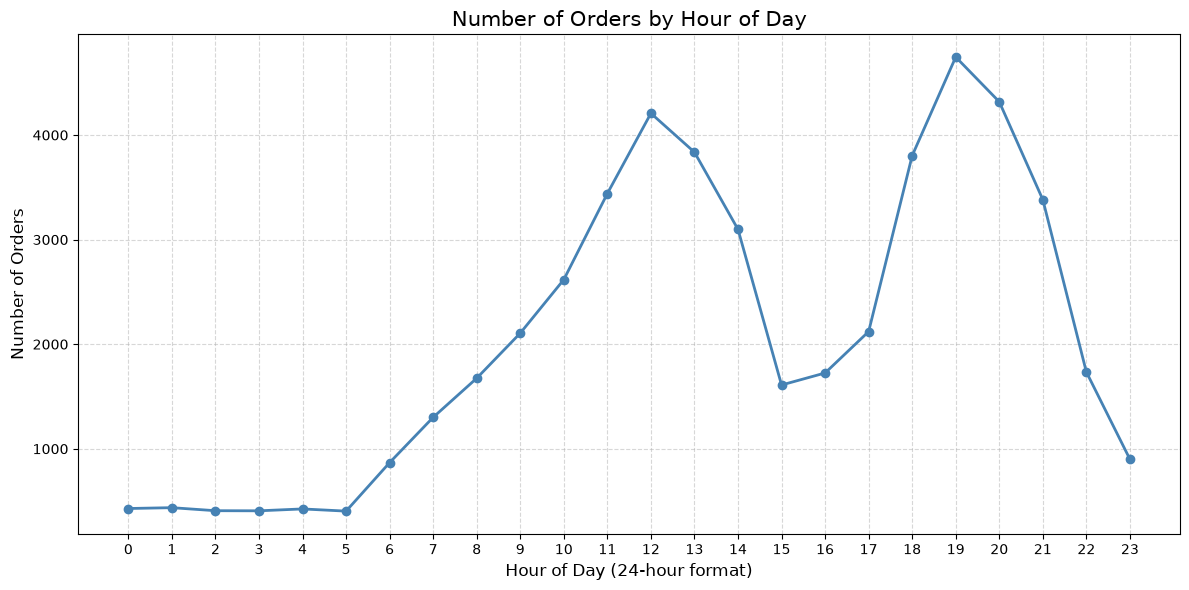

In [44]:
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_orders.index,
    hourly_orders.values,
    marker='o',
    linestyle='-',
    color='steelblue',
    linewidth=2
)

plt.title('Number of Orders by Hour of Day', fontsize=15)
plt.xlabel('Hour of Day (24-hour format)', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: The analysis shows that 7 PM (19:00) is the peak ordering hour, with approximately 4,750 orders, followed by 8 PM (20:00) with around 4,300 orders. A second major peak occurs at 12 PM (noon), with approximately 4,200 orders. Order volume rises steadily through the morning, reaches a lunchtime peak, declines during the afternoon, and increases sharply again in the evening.

The high order volume around noon may be associated with lunch breaks and midday meal demand, while the evening peak may be driven by customers ordering dinner after work or other daily activities. In contrast, order volumes are lowest during the early morning hours, particularly between midnight and 5 AM, potentially because fewer customers order food during these hours.

5. Which day of the week generates the most orders?

In [45]:
weekday_orders = (
    df.groupby('day_of_week')['order_id']
    .nunique()
)

# Arrange weekdays in calendar order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

weekday_orders = weekday_orders.reindex(weekday_order)

print("Number of Orders by Day of the Week:")
print(weekday_orders)

print("\nDay with the Highest Number of Orders:")
print(weekday_orders.idxmax(), "-", weekday_orders.max(), "orders")

Number of Orders by Day of the Week:
day_of_week
Monday       6665
Tuesday      6671
Wednesday    8212
Thursday     8472
Friday       6624
Saturday     6698
Sunday       6658
Name: order_id, dtype: int64

Day with the Highest Number of Orders:
Thursday - 8472 orders


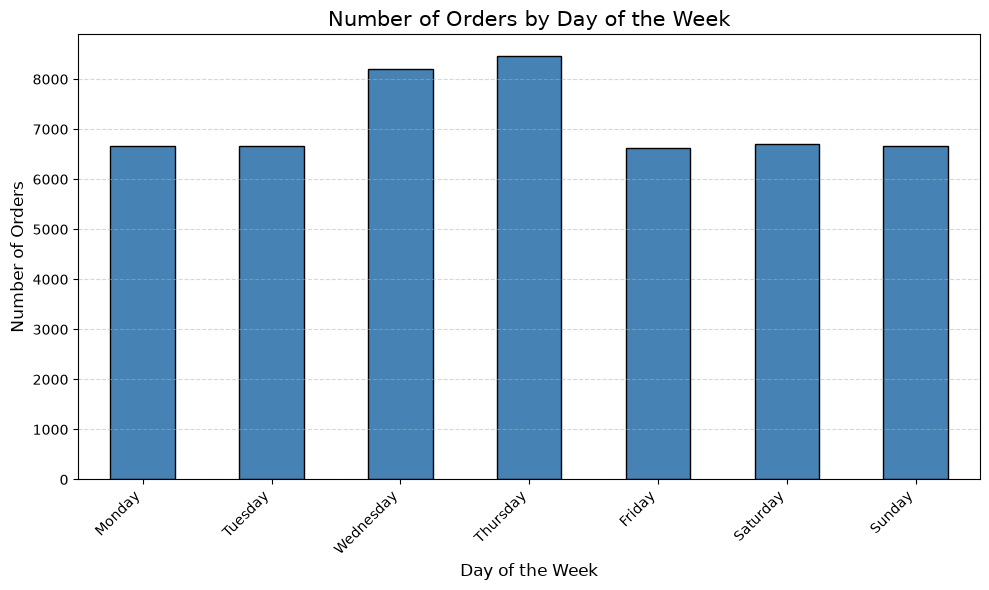

In [46]:
plt.figure(figsize=(10, 6))

weekday_orders.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Number of Orders by Day of the Week', fontsize=15)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Thursday generates the highest number of orders, with approximately 8,450 orders, followed by Wednesday with around 8,200 orders. Monday and Tuesday each record approximately 6,650 orders, while Friday, Saturday, and Sunday have roughly 6,600–6,700 orders.

The higher order volume on Wednesday and Thursday may indicate increased demand during the middle of the week. This could be associated with customers' work schedules, meal routines, or other purchasing habits. The relatively lower order counts on Monday, Tuesday, and the weekend suggest that demand is more moderate on those days. However, the chart shows the pattern of orders but does not establish the reasons behind it.

6. How does order volume vary between weekdays and weekends?


In [50]:
# Group orders into weekdays and weekends
day_type_orders = (
    df.groupby('is_weekend')['order_id']
    .nunique()
    .rename(index={False: 'Weekday', True: 'Weekend'})
    .reindex(['Weekday', 'Weekend'])
)

print("Number of Orders: Weekdays vs Weekends")
print(day_type_orders)

print("\nPercentage of Total Orders:")
print((day_type_orders / day_type_orders.sum() * 100).round(2))

Number of Orders: Weekdays vs Weekends
is_weekend
Weekday    36644
Weekend    13356
Name: order_id, dtype: int64

Percentage of Total Orders:
is_weekend
Weekday    73.29
Weekend    26.71
Name: order_id, dtype: float64


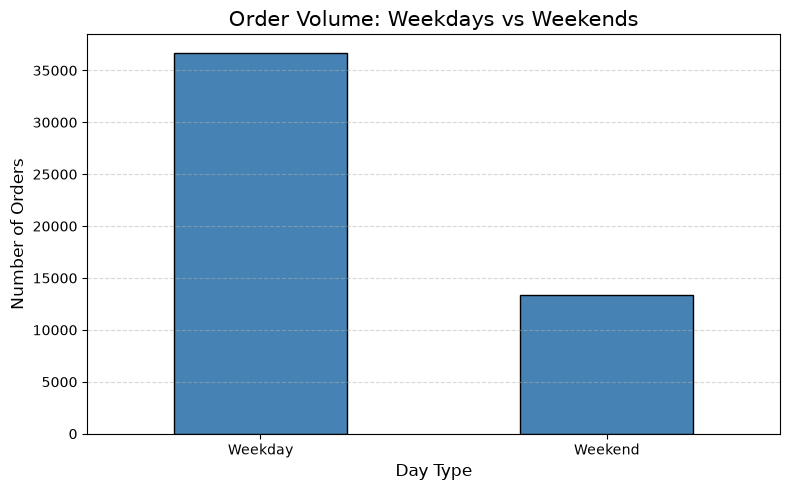

In [51]:

plt.figure(figsize=(8, 5))

day_type_orders.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Order Volume: Weekdays vs Weekends', fontsize=15)
plt.xlabel('Day Type', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: weekdays generate significantly more orders than weekends. Weekdays account for 36,644 orders (approximately 73.29%), while weekends account for 13,356 orders (approximately 26.71%).

This difference may be related to customers ordering food during working days because of busy schedules, limited time for cooking, or workplace meal needs. Weekend demand may be lower because some customers prefer home-cooked meals or dining out. These are possible explanations; the chart does not establish the exact reasons.

7. Which meal periods generate the highest revenue?

In [52]:

# Classify orders based on order_hour
conditions = [
    df['order_hour'].between(6, 10),
    df['order_hour'].between(11, 14),
    df['order_hour'].between(15, 17),
    df['order_hour'].between(18, 22)
]

meal_periods = ['Breakfast', 'Lunch', 'Evening', 'Dinner']

df['meal_period'] = np.select(
    conditions,
    meal_periods,
    default='Other'
)

# Calculate revenue from completed orders only
completed_df = df[df['order_status'] == 'Completed'].copy()

meal_revenue = (
    completed_df.groupby('meal_period')['order_total']
    .sum()
    .reindex(['Breakfast', 'Lunch', 'Evening', 'Dinner', 'Other'])
)

print("Total Revenue by Meal Period:")
print(meal_revenue.round(2))

print("\nMeal Period with Highest Revenue:")
print(meal_revenue.idxmax(), "-", round(meal_revenue.max(), 2))

Total Revenue by Meal Period:
meal_period
Breakfast    319871.23
Lunch        545762.35
Evening      203891.55
Dinner       673846.63
Other        130804.81
Name: order_total, dtype: float64

Meal Period with Highest Revenue:
Dinner - 673846.63


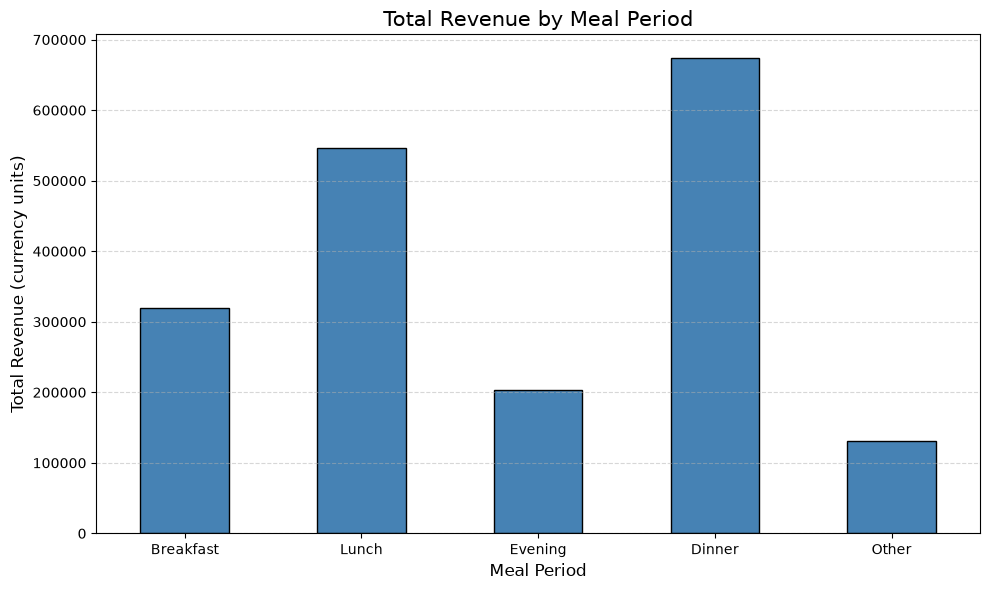

In [53]:
plt.figure(figsize=(10, 6))

meal_revenue.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Revenue by Meal Period', fontsize=15)
plt.xlabel('Meal Period', fontsize=12)
plt.ylabel('Total Revenue (currency units)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: dinner generates the highest revenue, at approximately 675,000 currency units, followed by lunch at around 545,000. Breakfast contributes approximately 320,000, while evening generates around 202,000. The Other category, covering overnight hours, records the lowest revenue at approximately 130,000 currency units.

Dinner's leading revenue may be associated with customers ordering their main evening meals after work or spending more per order during this period. Lunch also generates substantial revenue, potentially due to midday meal demand. Breakfast and evening generate less revenue, while overnight demand appears comparatively low.

8. Which customer types generate the highest total revenue?

In [56]:
completed_df = df[df['order_status'] == 'Completed'].copy()

customer_type_revenue = (
    completed_df.groupby('customer_type')['order_total']
    .sum()
    .sort_values(ascending=False)
)

print("Total Revenue by Customer Type:")
print(customer_type_revenue.round(2))

print("\nCustomer Type with Highest Revenue:")
print(
    customer_type_revenue.idxmax(),
    "-",
    round(customer_type_revenue.max(), 2)
)

Total Revenue by Customer Type:
customer_type
Regular    977149.10
Premium    489486.50
New        407540.97
Name: order_total, dtype: float64

Customer Type with Highest Revenue:
Regular - 977149.1


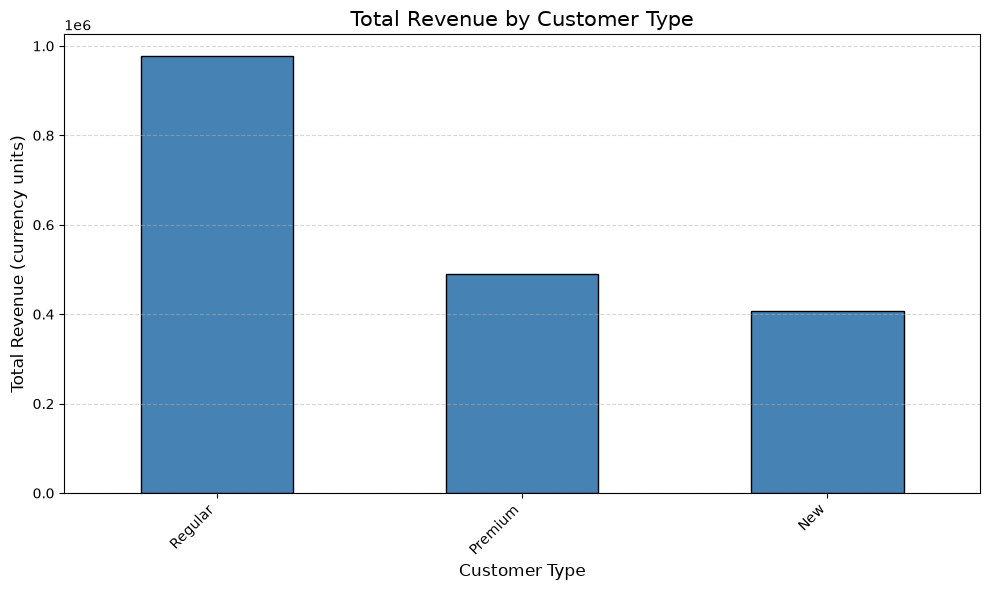

In [57]:
plt.figure(figsize=(10, 6))

customer_type_revenue.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Total Revenue by Customer Type', fontsize=15)
plt.xlabel('Customer Type', fontsize=12)
plt.ylabel('Total Revenue (currency units)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Regular customers generate the highest total revenue, contributing approximately 980,000 currency units. Premium customers rank second, generating around 490,000, while New customers contribute approximately 405,000 currency units.

Regular customers generate roughly twice the revenue of Premium customers and substantially more than New customers. One possible reason is that regular customers place orders more frequently because they already use the platform. Premium customers contribute the second-highest revenue, while new customers may generate less revenue because they have had fewer opportunities to place orders.

9. How does order frequency vary across customer age groups?

In [58]:

# Create age groups
age_bins = [0, 25, 35, 45, 55, float('inf')]
age_labels = ['18–25', '26–35', '36–45', '46–55', '56+']

df['age_group'] = pd.cut(
    df['customer_age'],
    bins=age_bins,
    labels=age_labels,
    right=True
)

# Count orders for each age group
age_group_orders = (
    df.groupby('age_group', observed=False)['order_id']
    .nunique()
    .reindex(age_labels)
)

print("Number of Orders by Customer Age Group:")
print(age_group_orders)

print("\nAge Group with the Highest Number of Orders:")
print(age_group_orders.idxmax(), "-", age_group_orders.max(), "orders")

Number of Orders by Customer Age Group:
age_group
18–25    21252
26–35    18715
36–45     9757
46–55      276
56+          0
Name: order_id, dtype: int64

Age Group with the Highest Number of Orders:
18–25 - 21252 orders


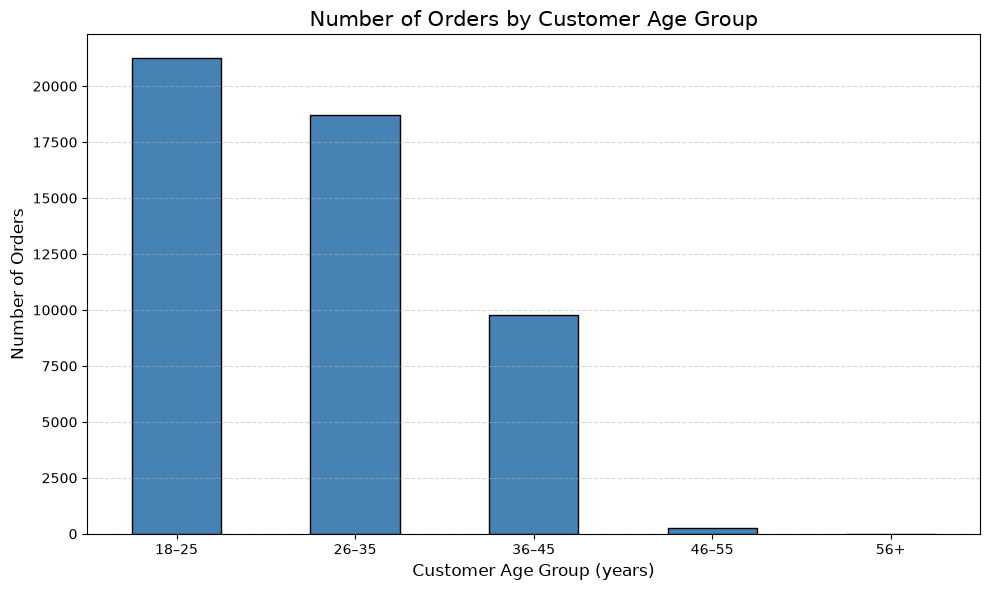

In [59]:
plt.figure(figsize=(10, 6))

age_group_orders.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Number of Orders by Customer Age Group', fontsize=15)
plt.xlabel('Customer Age Group (years)', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: 18–25 age group generates the highest number of orders, with approximately 21,200 orders, followed by the 26–35 age group with around 18,700 orders. The 36–45 age group contributes approximately 9,800 orders, while the 46–55 group accounts for only a few hundred orders. The 56+ group contributes almost no orders.

This pattern suggests that food delivery activity in the dataset is concentrated among younger customers, particularly those aged 18–35. Possible reasons include greater familiarity with digital ordering platforms, convenience-oriented lifestyles, and frequent use of food delivery services. The lower order counts among older age groups may reflect a smaller representation of these customers in the dataset or differences in ordering habits.

10. What percentage of orders comes from each customer type?

In [60]:
customer_type_percentage = (
    df['customer_type']
    .value_counts(normalize=True)
    .mul(100)
)

print("Percentage of Orders by Customer Type:")
print(customer_type_percentage.round(2))

Percentage of Orders by Customer Type:
customer_type
Regular    50.20
Premium    29.45
New        20.35
Name: proportion, dtype: float64


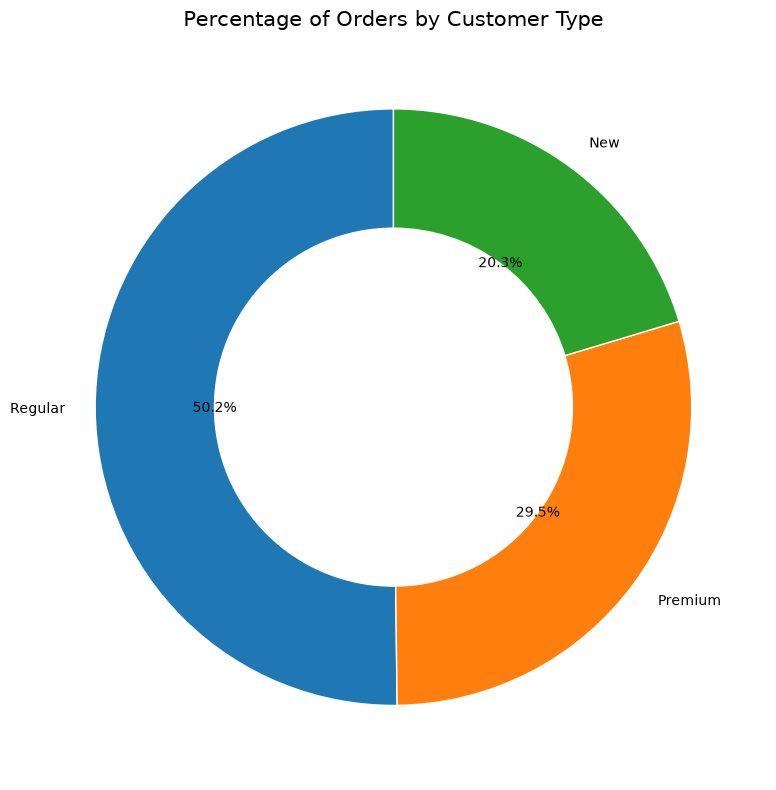

In [61]:
plt.figure(figsize=(8, 8))

plt.pie(
    customer_type_percentage,
    labels=customer_type_percentage.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

plt.title('Percentage of Orders by Customer Type', fontsize=15)
plt.tight_layout()
plt.show()

Conclusion: Regular customers contribute the highest percentage of orders, accounting for 50.2% of all orders. Premium customers contribute 29.5%, while New customers account for 20.3%.

Regular customers generate approximately half of all orders, suggesting that existing customers play an important role in maintaining the platform's order volume. Premium customers contribute nearly one-third, indicating that this segment also represents a substantial share of activity. New customers account for about one-fifth of orders, showing that customer acquisition contributes to the platform's business but is smaller than the contribution from existing customer segments.

11. Which restaurant categories receive the highest average customer ratings?

In [63]:
completed_df = df[df['order_status'] == 'Completed'].copy()

category_ratings = (
    completed_df.groupby('restaurant_primary_category')['customer_rating']
    .mean()
    .sort_values(ascending=False)
)

print("Average Customer Rating by Restaurant Category:")
print(category_ratings.round(2))

print("\nTop-Rated Restaurant Category:")
print(category_ratings.idxmax(), "-", round(category_ratings.max(), 2))

Average Customer Rating by Restaurant Category:
restaurant_primary_category
Healthy    4.32
Burger     4.30
Asian      4.30
Dessert    4.30
Local      4.29
Pizza      4.28
Name: customer_rating, dtype: float64

Top-Rated Restaurant Category:
Healthy - 4.32


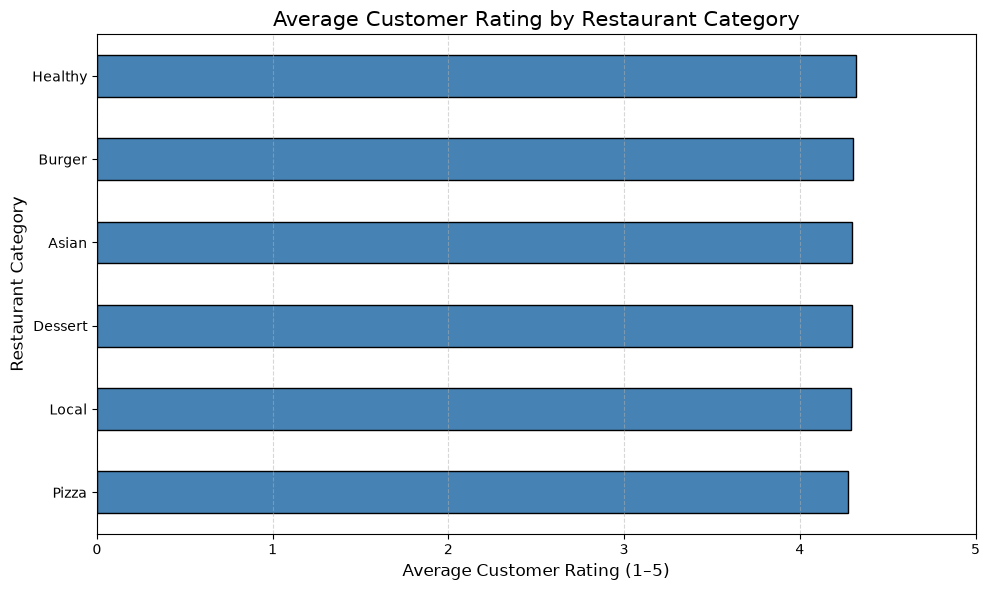

In [64]:
plt.figure(figsize=(10, 6))

category_ratings.sort_values().plot(
    kind='barh',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Customer Rating by Restaurant Category', fontsize=15)
plt.xlabel('Average Customer Rating (1–5)', fontsize=12)
plt.ylabel('Restaurant Category', fontsize=12)
plt.xlim(0, 5)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Healthy restaurants receive the highest average customer rating, at approximately 4.32 out of 5. Burger, Asian, Dessert, and Local categories follow closely at around 4.30, while Pizza has a slightly lower average rating of approximately 4.28.

The differences between categories are very small, indicating that customer satisfaction is consistently high across all six restaurant categories. Healthy restaurants may perform slightly better because of food quality, customer preferences, or overall ordering experiences. However, these are possible explanations; the chart does not establish the specific reasons for the rating differences.

12. Which restaurant types have the highest average number of items per order?

In [66]:
completed_df = df[df['order_status'] == 'Completed'].copy()

restaurant_items = (
    completed_df.groupby('restaurant_type')['items_count']
    .mean()
    .sort_values(ascending=False)
)

print("Average Number of Items per Order by Restaurant Type:")
print(restaurant_items.round(2))

print("\nRestaurant Type with Highest Average Items:")
print(restaurant_items.idxmax(), "-", round(restaurant_items.max(), 2))

Average Number of Items per Order by Restaurant Type:
restaurant_type
Fast Food        2.92
Cafe             2.91
Casual Dining    2.89
Fine Dining      2.85
Name: items_count, dtype: float64

Restaurant Type with Highest Average Items:
Fast Food - 2.92


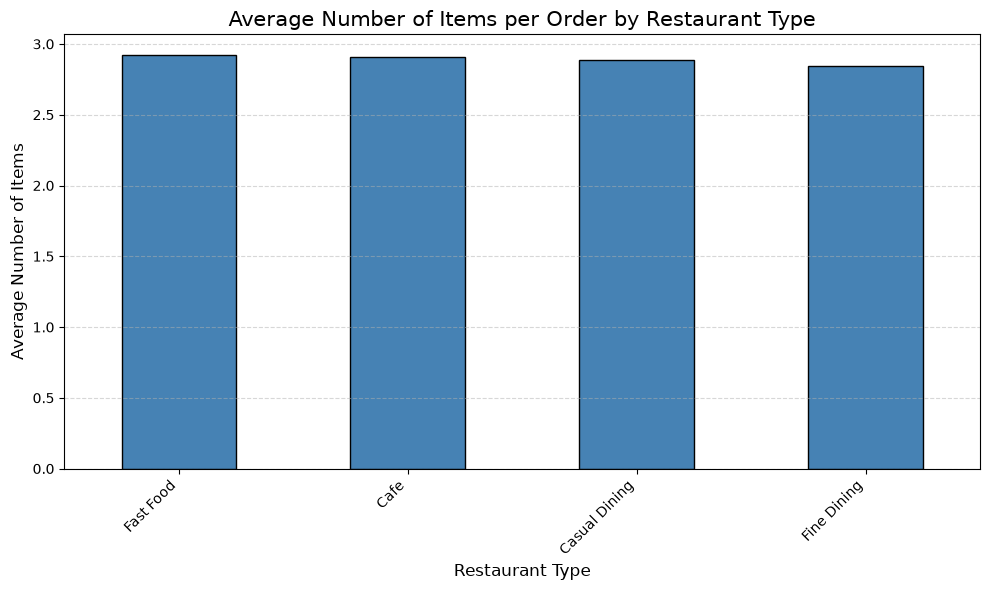

In [68]:
plt.figure(figsize=(10, 6))

restaurant_items.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Number of Items per Order by Restaurant Type', fontsize=15)
plt.xlabel('Restaurant Type', fontsize=12)
plt.ylabel('Average Number of Items', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Fast Food restaurants have the highest average number of items per order, at approximately 2.92 items, closely followed by Cafes at around 2.91 items. Casual Dining averages approximately 2.88 items, while Fine Dining has the lowest average at around 2.84 items.

The differences between restaurant types are very small, indicating that customers order approximately three items per order across all four types. Fast Food restaurants may have a slightly higher average because customers often purchase combinations of main items, sides, and drinks. Fine Dining's marginally lower average may reflect differences in menu structure or ordering patterns. These are possible explanations, not causes confirmed by the chart.

13. Which traffic conditions are associated with the longest actual delivery times?

In [71]:
completed_df = df[df['order_status'] == 'Completed'].copy()

traffic_delivery = (
    completed_df.groupby('traffic_level')['actual_delivery_time_minutes']
    .mean()
    .sort_values(ascending=False)
)

print("Average Actual Delivery Time by Traffic Level:")
print(traffic_delivery.round(2))

print("\nTraffic Condition with the Longest Average Delivery Time:")
print(traffic_delivery.idxmax(), "-", round(traffic_delivery.max(), 2), "minutes")

Average Actual Delivery Time by Traffic Level:
traffic_level
High      39.89
Medium    35.02
Low       30.59
Name: actual_delivery_time_minutes, dtype: float64

Traffic Condition with the Longest Average Delivery Time:
High - 39.89 minutes


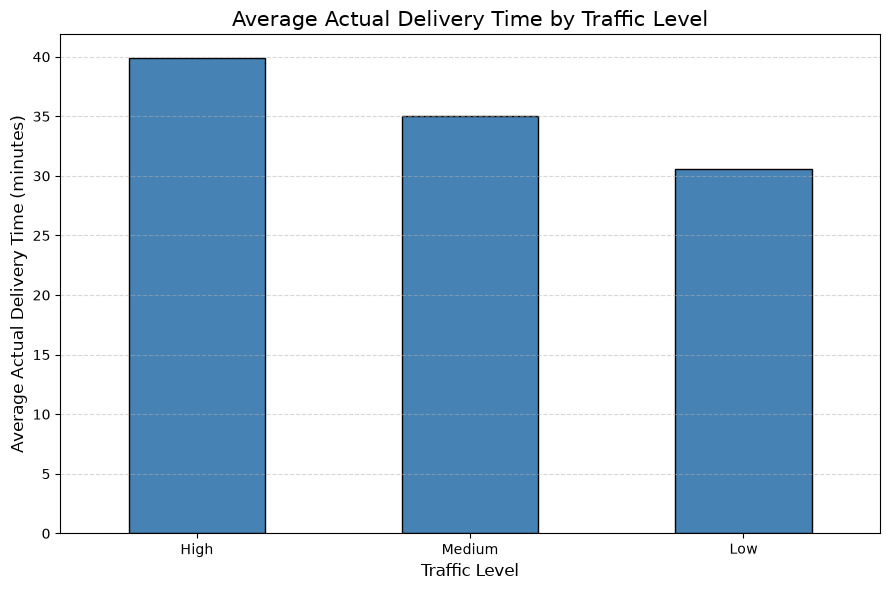

In [72]:
plt.figure(figsize=(9, 6))

traffic_delivery.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Actual Delivery Time by Traffic Level', fontsize=15)
plt.xlabel('Traffic Level', fontsize=12)
plt.ylabel('Average Actual Delivery Time (minutes)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: high traffic is associated with the longest average actual delivery time, at approximately 40 minutes. Medium traffic has an average delivery time of around 35 minutes, while low traffic has the shortest average at approximately 30.5 minutes.

This pattern suggests that delivery times increase as traffic becomes heavier. High traffic can slow vehicle movement, cause congestion at intersections, and make it harder for delivery partners to reach customers on time. Under low-traffic conditions, drivers can generally travel more efficiently, resulting in shorter delivery times.

14. How does weather affect average delivery time?

In [73]:
completed_df = df[df['order_status'] == 'Completed'].copy()

weather_delivery = (
    completed_df.groupby('weather')['actual_delivery_time_minutes']
    .mean()
    .sort_values(ascending=False)
)

print("Average Actual Delivery Time by Weather:")
print(weather_delivery.round(2))

print("\nWeather Condition with the Longest Average Delivery Time:")
print(
    weather_delivery.idxmax(),
    "-",
    round(weather_delivery.max(), 2),
    "minutes"
)

Average Actual Delivery Time by Weather:
weather
Storm     47.07
Rain      39.16
Cloudy    35.12
Clear     33.56
Name: actual_delivery_time_minutes, dtype: float64

Weather Condition with the Longest Average Delivery Time:
Storm - 47.07 minutes


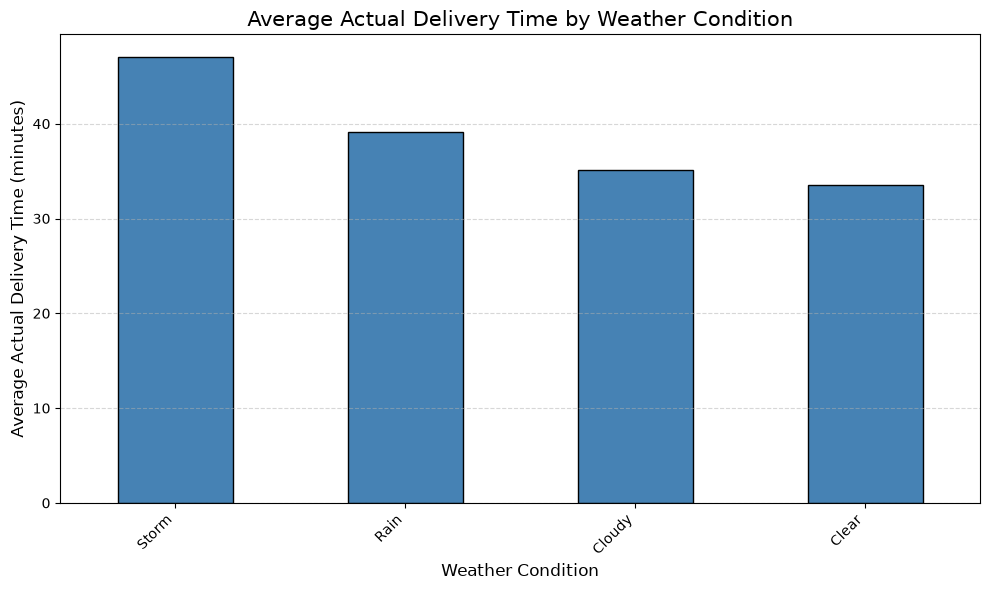

In [74]:
plt.figure(figsize=(10, 6))

weather_delivery.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Actual Delivery Time by Weather Condition', fontsize=15)
plt.xlabel('Weather Condition', fontsize=12)
plt.ylabel('Average Actual Delivery Time (minutes)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Storm conditions are associated with the longest average actual delivery time, at approximately 47 minutes. Rain follows at around 39 minutes, while Cloudy conditions average about 35 minutes. Clear weather has the shortest average delivery time, at approximately 33.5 minutes.

This pattern suggests that adverse weather conditions are associated with longer delivery times. Storms may reduce road visibility, make driving more difficult, and force delivery partners to travel more cautiously. Rain can also affect road conditions and traffic flow. In contrast, clear weather generally provides more favourable conditions for travel, which may help drivers complete deliveries faster.

15. What percentage of orders are delivered late?

In [75]:

# Keep orders with valid actual delivery time and late-delivery status
valid_delivery_df = df[
    df['actual_delivery_time_minutes'].notna()
    & df['late_delivery'].notna()
].copy()

# Calculate late and on-time order counts
late_counts = (
    valid_delivery_df['late_delivery']
    .astype(int)
    .value_counts()
    .reindex([1, 0], fill_value=0)
)

late_count = late_counts.loc[1]
on_time_count = late_counts.loc[0]
total_valid_orders = late_count + on_time_count

late_percentage = late_count / total_valid_orders * 100
on_time_percentage = on_time_count / total_valid_orders * 100

print("Total orders with valid delivery data:", total_valid_orders)
print("Late orders:", late_count)
print("On-time orders:", on_time_count)
print(f"Late delivery percentage: {late_percentage:.2f}%")
print(f"On-time delivery percentage: {on_time_percentage:.2f}%")

Total orders with valid delivery data: 49132
Late orders: 17968
On-time orders: 31164
Late delivery percentage: 36.57%
On-time delivery percentage: 63.43%


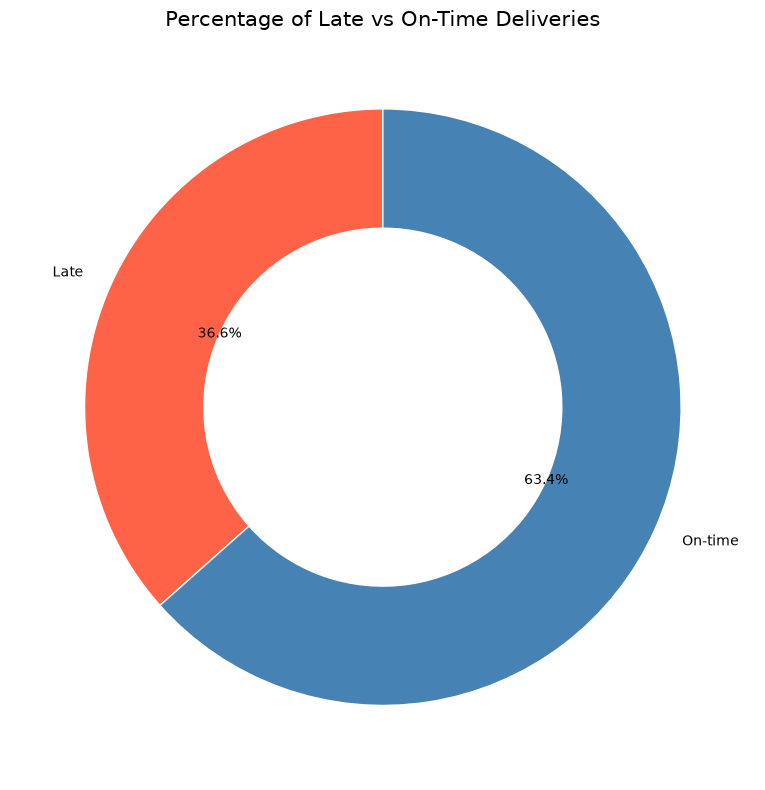

In [76]:
labels = ['Late', 'On-time']
values = [late_count, on_time_count]

plt.figure(figsize=(8, 8))

plt.pie(
    values,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['tomato', 'steelblue'],
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

plt.title('Percentage of Late vs On-Time Deliveries', fontsize=15)
plt.tight_layout()
plt.show()

Conclusion: 36.6% of valid deliveries are late, while 63.4% are delivered on time. This means that more than one-third of completed deliveries exceed the dataset's defined lateness threshold, indicating a notable delivery-performance challenge.

One possible reason for late deliveries is heavy traffic, as your earlier analysis showed that average delivery time increases from approximately 30.5 minutes under low traffic to 40 minutes under high traffic. Adverse weather may also contribute: deliveries during storms take approximately 47 minutes on average, compared with around 33.5 minutes in clear weather. These factors may help explain the late-delivery rate, although their individual contributions have not yet been quantified.

16. How does delivery distance affect actual delivery time?

In [77]:
completed_df = df[
    (df['order_status'] == 'Completed') &
    (df['actual_delivery_time_minutes'].notna()) &
    (df['distance_km'].notna())
].copy()

# Calculate correlation
correlation = completed_df['distance_km'].corr(
    completed_df['actual_delivery_time_minutes']
)

print("Correlation between Distance and Actual Delivery Time:",
      round(correlation, 3))

Correlation between Distance and Actual Delivery Time: 0.767


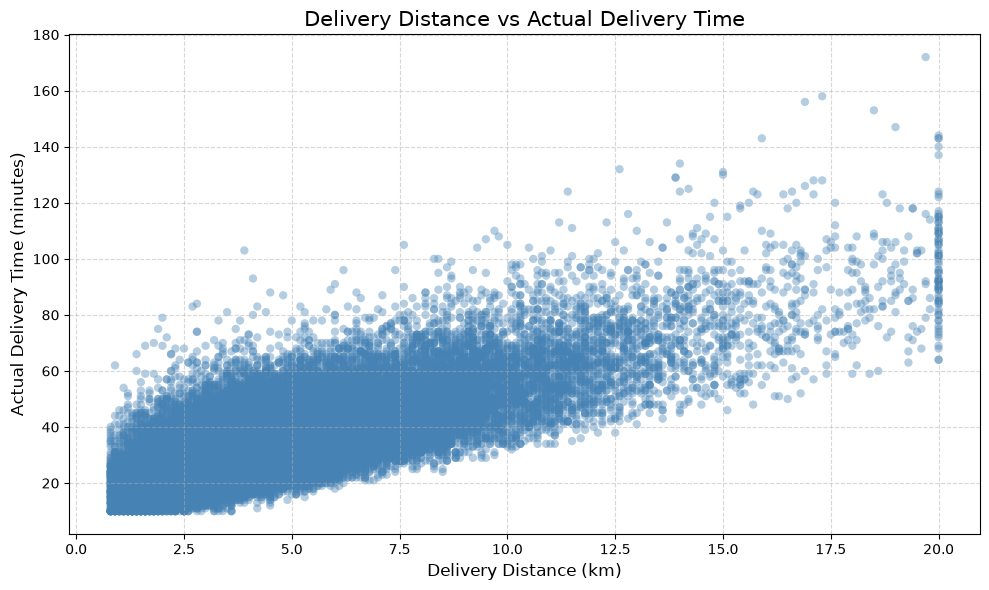

In [78]:
plt.figure(figsize=(10, 6))

plt.scatter(
    completed_df['distance_km'],
    completed_df['actual_delivery_time_minutes'],
    color='steelblue',
    edgecolor='none',
    alpha=0.4
)

plt.title('Delivery Distance vs Actual Delivery Time', fontsize=15)
plt.xlabel('Delivery Distance (km)', fontsize=12)
plt.ylabel('Actual Delivery Time (minutes)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: The scatter plot shows a positive relationship between delivery distance and actual delivery time. In general, orders travelling longer distances tend to take more time to reach customers.

Most shorter-distance deliveries are completed in less time, while longer-distance deliveries show higher delivery times and greater variation. For example, deliveries over approximately 15 km frequently take 60–100 minutes or more, with a few exceeding 150 minutes. This suggests that longer journeys are generally associated with longer delivery durations.

17. Which factors are associated with longer restaurant preparation times?

In [79]:

prep_by_type = (
    df.groupby('restaurant_type')['restaurant_preparation_time_minutes']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .sort_values('mean', ascending=False)
)

print("Preparation Time Statistics by Restaurant Type:")
print(prep_by_type.round(2))

Preparation Time Statistics by Restaurant Type:
                 count   mean  median  min  max
restaurant_type                                
Fine Dining       1204  28.69    26.0    7   73
Casual Dining    13063  18.97    18.0    5   54
Fast Food        27593  14.44    13.0    5   43
Cafe              8140  11.87    11.0    5   33


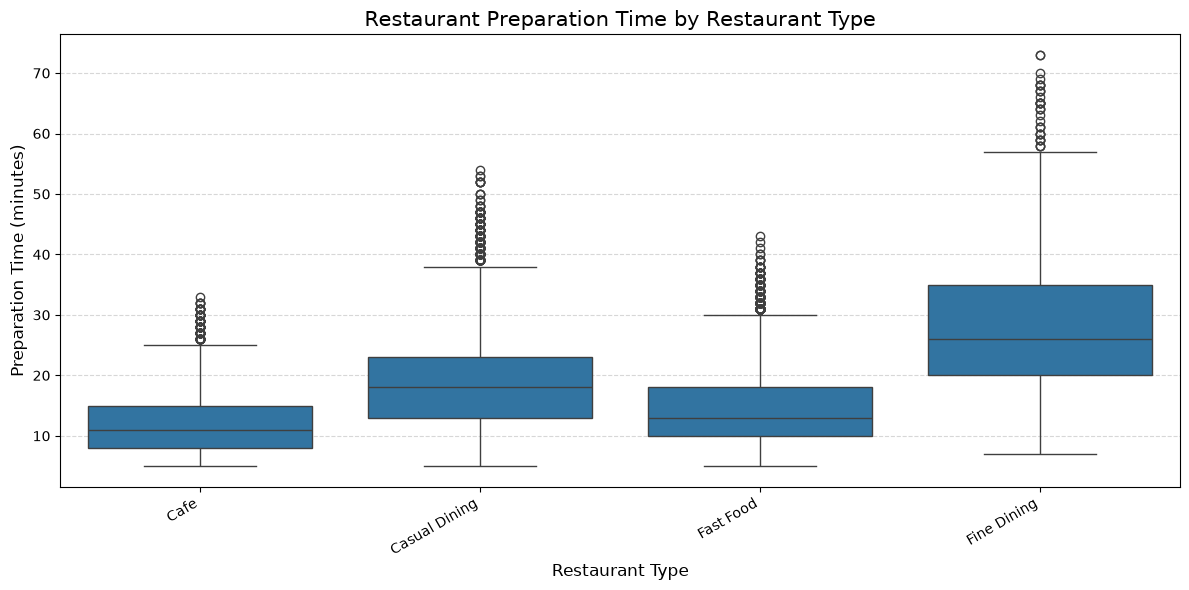

In [80]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='restaurant_type',
    y='restaurant_preparation_time_minutes'
)

plt.title('Restaurant Preparation Time by Restaurant Type', fontsize=15)
plt.xlabel('Restaurant Type', fontsize=12)
plt.ylabel('Preparation Time (minutes)', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: The box plot shows that Fine Dining restaurants have the longest preparation times, with a median of approximately 26 minutes, followed by Casual Dining at around 18 minutes. Fast Food restaurants have a median of about 13 minutes, while Cafes have the shortest median at approximately 11 minutes.

Fine Dining also has the widest spread of preparation times, with several outliers extending beyond 60 minutes and reaching approximately 73 minutes. Casual Dining also shows considerable variation, with some preparation times exceeding 50 minutes. In comparison, Cafes and Fast Food generally have shorter preparation times, although both have some unusually long cases.

18. How does delivery partner experience relate to delivery time and customer ratings?

In [82]:

# Keep completed orders with valid delivery time and customer rating
valid_df = df[
    (df['order_status'] == 'Completed') &
    df['actual_delivery_time_minutes'].notna() &
    df['customer_rating'].notna() &
    df['delivery_partner_experience_months'].notna()
].copy()

# Define experience bands
experience_bins = [-1, 6, 12, 24, float('inf')]
experience_labels = [
    'Beginner (0–6 months)',
    'Intermediate (7–12 months)',
    'Experienced (13–24 months)',
    'Highly Experienced (25+ months)'
]

valid_df['experience_band'] = pd.cut(
    valid_df['delivery_partner_experience_months'],
    bins=experience_bins,
    labels=experience_labels
)

# Calculate average delivery time and customer rating
experience_analysis = (
    valid_df.groupby('experience_band', observed=False)
    .agg(
        order_count=('order_id', 'nunique'),
        avg_delivery_time=('actual_delivery_time_minutes', 'mean'),
        avg_customer_rating=('customer_rating', 'mean')
    )
    .reindex(experience_labels)
)

print("Delivery Partner Experience Analysis:")
print(experience_analysis.round(2))

Delivery Partner Experience Analysis:
                                 order_count  avg_delivery_time  \
experience_band                                                   
Beginner (0–6 months)                   5828              34.96   
Intermediate (7–12 months)              5101              35.33   
Experienced (13–24 months)             10266              35.32   
Highly Experienced (25+ months)        27937              35.10   

                                 avg_customer_rating  
experience_band                                       
Beginner (0–6 months)                           4.30  
Intermediate (7–12 months)                      4.29  
Experienced (13–24 months)                      4.30  
Highly Experienced (25+ months)                 4.29  


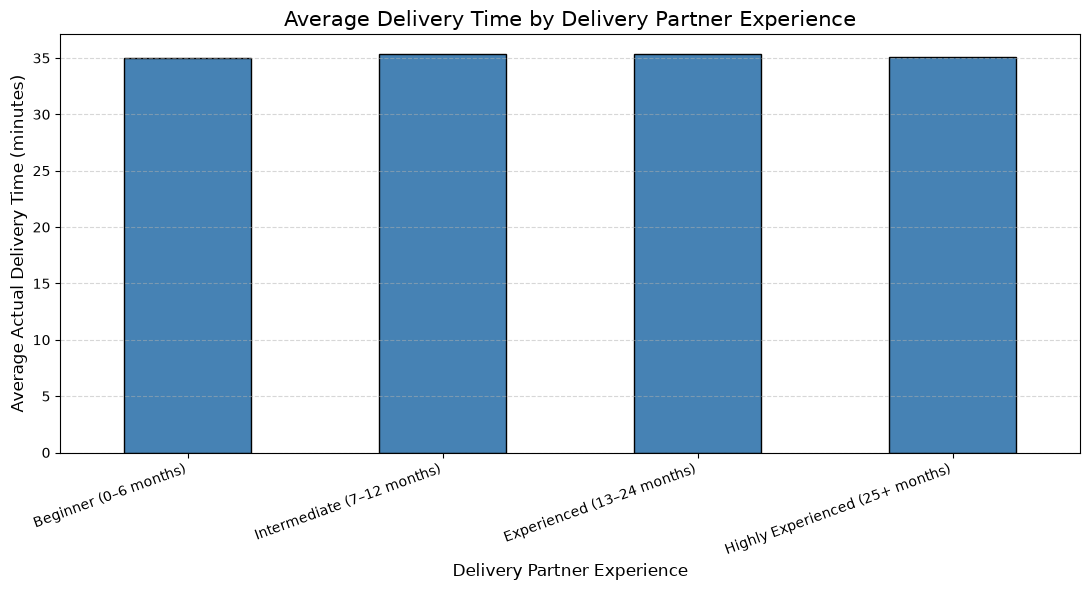

In [83]:
plt.figure(figsize=(11, 6))

experience_analysis['avg_delivery_time'].plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Delivery Time by Delivery Partner Experience', fontsize=15)
plt.xlabel('Delivery Partner Experience', fontsize=12)
plt.ylabel('Average Actual Delivery Time (minutes)', fontsize=12)
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

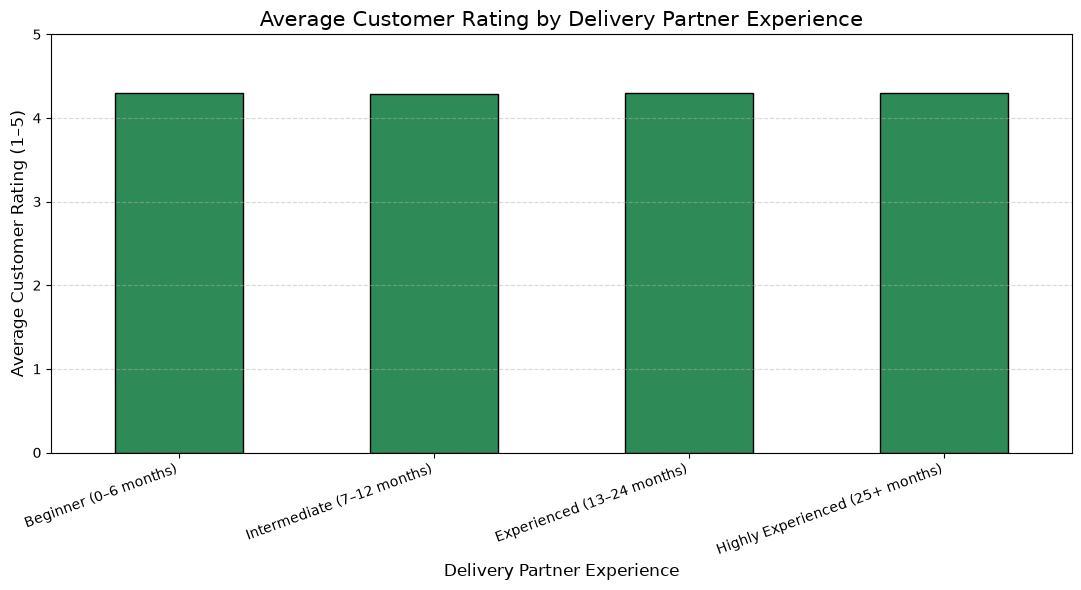

In [84]:
plt.figure(figsize=(11, 6))

experience_analysis['avg_customer_rating'].plot(
    kind='bar',
    color='seagreen',
    edgecolor='black'
)

plt.title('Average Customer Rating by Delivery Partner Experience', fontsize=15)
plt.xlabel('Delivery Partner Experience', fontsize=12)
plt.ylabel('Average Customer Rating (1–5)', fontsize=12)
plt.ylim(0, 5)
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: The analysis shows that delivery partner experience has very little association with average delivery time or customer ratings in this dataset.
- Average delivery time: All four experience groups have nearly identical average delivery times, around 35 minutes. Highly experienced partners do not appear to deliver substantially faster than beginners.
- Customer ratings: All four groups receive almost identical average customer ratings, approximately 4.3 out of 5. This suggests that customer satisfaction remains consistently high regardless of experience level.

19. What percentage of orders are completed versus cancelled?

In [85]:

# Count orders by status
status_counts = df['order_status'].value_counts()

# Calculate percentages
status_percentages = (
    df['order_status'].value_counts(normalize=True) * 100
)

print("Order Counts by Status:")
print(status_counts)

print("\nOrder Status Percentages:")
print(status_percentages.round(2))

Order Counts by Status:
order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

Order Status Percentages:
order_status
Completed    98.26
Cancelled     1.74
Name: proportion, dtype: float64


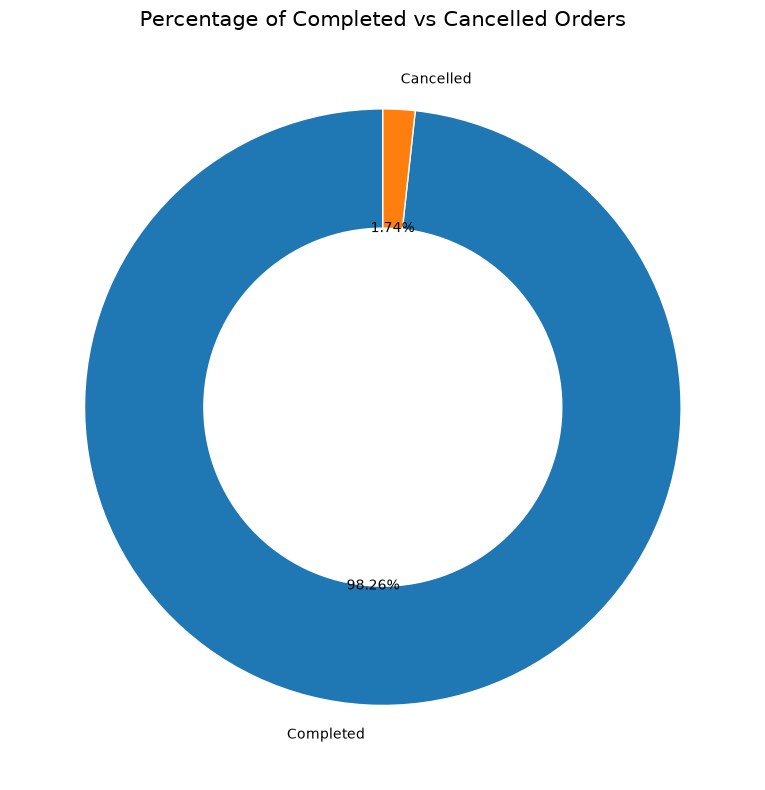

In [86]:
plt.figure(figsize=(8, 8))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.2f%%',
    startangle=90,
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

plt.title('Percentage of Completed vs Cancelled Orders', fontsize=15)
plt.tight_layout()
plt.show()

Conclusion: The donut chart shows that 98.26% of orders are completed, while only 1.74% are cancelled. Out of 50,000 total orders, 49,132 were completed and 868 were cancelled.

This indicates a very high order-completion rate, suggesting that the food delivery platform successfully fulfils the vast majority of orders. The low cancellation rate is a positive operational indicator, although it does not by itself measure customer satisfaction or delivery quality.

20. What are the most common reasons for order cancellations?

In [87]:

# Filter cancelled orders only
cancelled_df = df[df['order_status'] == 'Cancelled'].copy()

# Count cancellation reasons
cancellation_counts = (
    cancelled_df['cancellation_reason']
    .value_counts()
    .sort_values(ascending=False)
)

print("Order Cancellation Reasons:")
print(cancellation_counts)

print("\nPercentage of Cancelled Orders by Reason:")
print(
    (cancellation_counts / len(cancelled_df) * 100).round(2)
)

print("\nMost Common Cancellation Reason:")
print(cancellation_counts.idxmax(), "-", cancellation_counts.max(), "orders")

Order Cancellation Reasons:
cancellation_reason
Driver Unassigned         386
Restaurant Unavailable    160
Customer Cancelled        154
Changed Mind              153
Long Prep Delay            15
Name: count, dtype: int64

Percentage of Cancelled Orders by Reason:
cancellation_reason
Driver Unassigned         44.47
Restaurant Unavailable    18.43
Customer Cancelled        17.74
Changed Mind              17.63
Long Prep Delay            1.73
Name: count, dtype: float64

Most Common Cancellation Reason:
Driver Unassigned - 386 orders


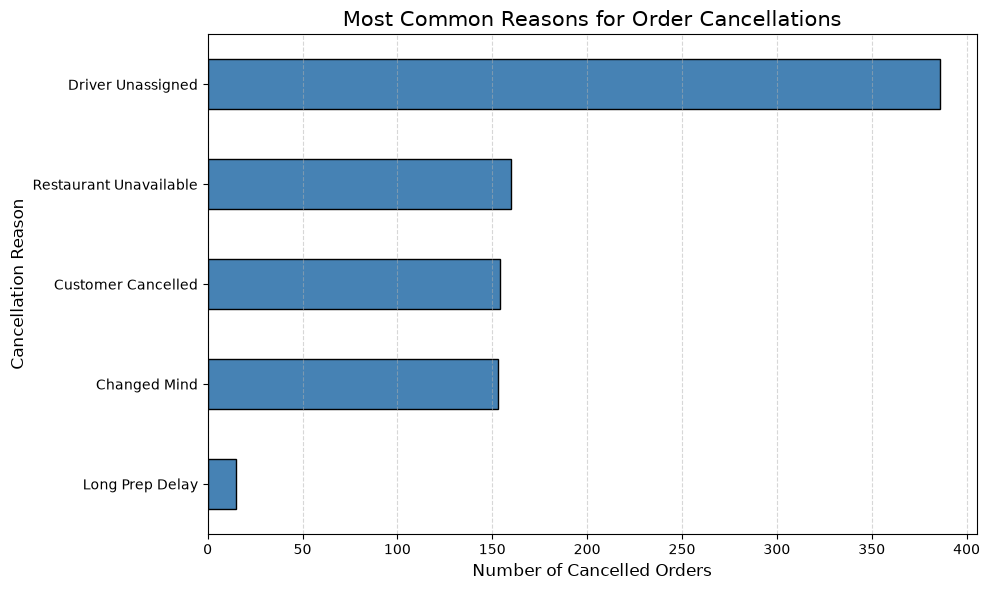

In [88]:
plt.figure(figsize=(10, 6))

cancellation_counts.sort_values().plot(
    kind='barh',
    color='steelblue',
    edgecolor='black'
)

plt.title('Most Common Reasons for Order Cancellations', fontsize=15)
plt.xlabel('Number of Cancelled Orders', fontsize=12)
plt.ylabel('Cancellation Reason', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: Driver Unassigned is the most common reason for order cancellation, accounting for approximately 385 orders. Restaurant Unavailable is the second most common reason, with around 160 cancellations, followed by Customer Cancelled and Changed Mind, each with approximately 150–155 cancellations. Long Prep Delay is the least common reason, with only around 15 cancellations.

The results suggest that delivery-partner assignment is the main operational issue associated with cancellations in this dataset. When a driver is not assigned, an order may be unable to proceed to delivery. Restaurant unavailability also contributes to cancellations, potentially because restaurants cannot fulfil orders when required. Customer cancellations and changes of mind represent another substantial group, while long preparation delays account for comparatively few cases.

21. How does delivery lateness affect customer ratings?

In [89]:

# Filter completed orders with valid customer ratings
valid_df = df[
    (df['order_status'] == 'Completed') &
    (df['late_delivery'].notna()) &
    (df['customer_rating'].notna())
].copy()

# Calculate average rating by delivery status
rating_by_lateness = (
    valid_df.groupby('late_delivery')['customer_rating']
    .mean()
    .rename(index={0: 'On-time', 1: 'Late'})
    .reindex(['On-time', 'Late'])
)

print("Average Customer Rating by Delivery Status:")
print(rating_by_lateness.round(2))

print("\nRating Difference (On-time - Late):",
      round(rating_by_lateness['On-time'] - rating_by_lateness['Late'], 2))

Average Customer Rating by Delivery Status:
late_delivery
On-time    4.56
Late       3.83
Name: customer_rating, dtype: float64

Rating Difference (On-time - Late): 0.73


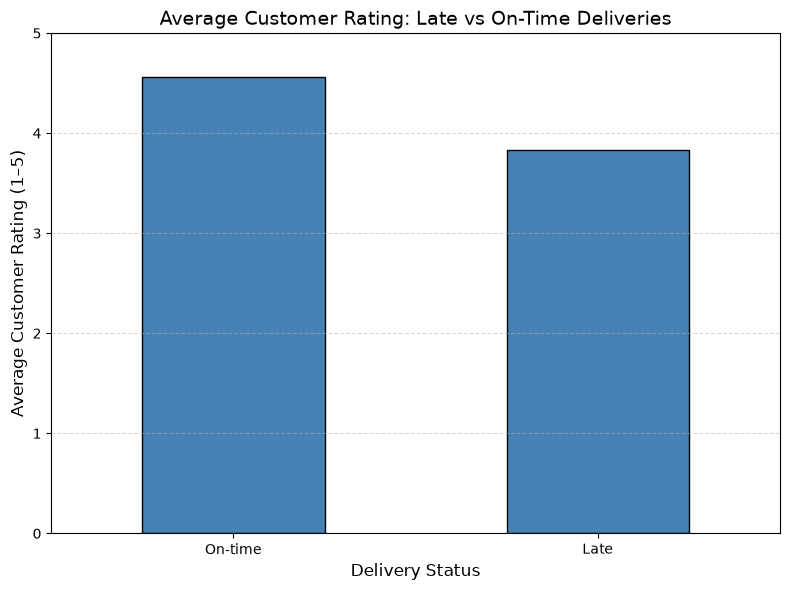

In [90]:
plt.figure(figsize=(8, 6))

rating_by_lateness.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Average Customer Rating: Late vs On-Time Deliveries', fontsize=14)
plt.xlabel('Delivery Status', fontsize=12)
plt.ylabel('Average Customer Rating (1–5)', fontsize=12)
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Conclusion: on-time deliveries receive higher average customer ratings than late deliveries. On-time orders have an average rating of approximately 4.55 out of 5, while late orders receive around 3.83 out of 5.

This represents a difference of approximately 0.72 rating points, indicating a noticeable association between delivery punctuality and customer satisfaction.

**Final Conclusion:**


Overall, the EDA indicates that the platform generates revenue primarily through a combination of strong evening demand, particular restaurant categories, and repeat customer activity. At the same time, delivery performance presents opportunities for improvement, particularly in relation to traffic, adverse weather, delivery distance, restaurant preparation time, and driver assignment. The association between late deliveries and lower customer ratings highlights the importance of reliable delivery estimates and efficient operations.

These findings provide a foundation for data-driven decisions in marketing, customer retention, restaurant coordination, and delivery management. Since this is an exploratory analysis, the observed relationships should not automatically be interpreted as causal; further statistical analysis would help confirm the strength and significance of the patterns identified.